Using device: cpu


c:\Users\rauna\OneDrive\Desktop\BT23F05F048\generative-ai-practicals\venv\Lib\site-packages\diffusers\utils\deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

c:\Users\rauna\OneDrive\Desktop\BT23F05F048\generative-ai-practicals\venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\rauna\.cache\huggingface\hub\models--stable-diffusion-v1-5--stable-diffusion-v1-5. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

c:\Users\rauna\OneDrive\Desktop\BT23F05F048\generative-ai-practicals\venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\rauna\.cache\huggingface\hub. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

  0%|          | 0/15 [00:00<?, ?it/s]

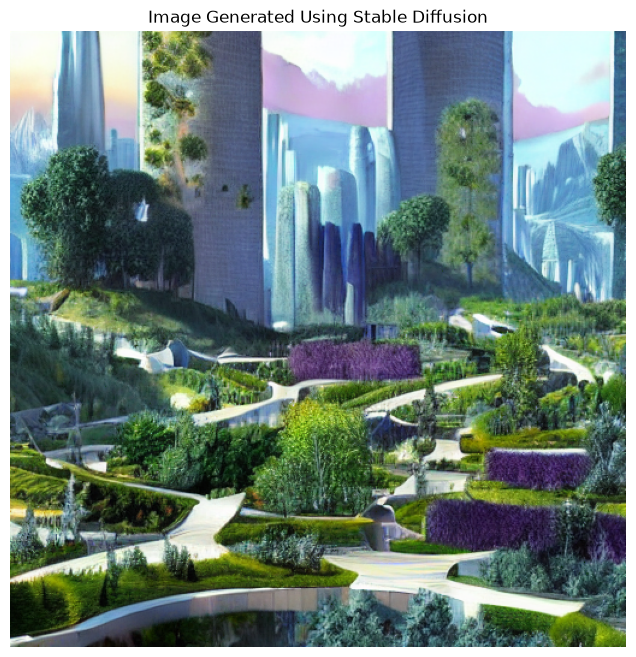

Image saved as generated_image.png


In [2]:
import torch
import matplotlib.pyplot as plt
from diffusers import StableDiffusionPipeline

# Automatically select GPU or CPU
device = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
dtype = torch.float16 if device == "cuda" else torch.float32

print("Using device:", device)

# Load Stable Diffusion model
model_id = "stable-diffusion-v1-5/stable-diffusion-v1-5"

pipe = StableDiffusionPipeline.from_pretrained(
    model_id,
    torch_dtype=dtype
)

pipe = pipe.to(device)
pipe.enable_attention_slicing()

# Text prompt
prompt = "A beautiful futuristic city with green gardens, modern buildings, mountains, realistic digital art"

# Generate image
image = pipe(
    prompt,
    num_inference_steps=15,
    guidance_scale=7.5
).images[0]

# Display image
plt.figure(figsize=(8, 8))
plt.imshow(image)
plt.axis("off")
plt.title("Image Generated Using Stable Diffusion")
plt.show()

# Save image
image.save("generated_image.png")
print("Image saved as generated_image.png")